In [1]:
# ============================================================
# 08_MODEL_OPTIMISATION AND VALIDATION
# Customer Churn Prediction
# ============================================================

import os
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.pipeline import Pipeline

from sklearn.feature_selection import RFE

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

OUTPUT_DIR = "model_optimisation_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("MODEL OPTIMISATION & VALIDATION")
print("=" * 70)

MODEL OPTIMISATION & VALIDATION


In [3]:
# ============================================================
# LOAD FEATURE-ENGINEERED DATASET
# ============================================================

df = pd.read_csv(
    "customer_churn_feature_engineered.csv"
)

print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (10000, 45)

First 5 Rows:


,gender,age,country,city,customer_segment,tenure_months,signup_channel,contract_type,monthly_logins,weekly_active_days,...,revenue_per_login,complaint_severity,activity_index,payment_risk,nps_scaled,csat_scaled,customer_satisfaction_index,inactivity_score,complaint_ratio,feature_adoption_rate
0,male,68,bangladesh,london,sme,22,web,monthly,26,7,...,1.153846,53.417439,82.336604,1,0.635,0.75,0.6925,0.304348,0.173913,0.333333
1,female,57,canada,sydney,individual,9,mobile,monthly,7,5,...,4.285714,25.140088,134.231948,3,0.405,0.25,0.3275,0.200000,0.100000,0.066667
2,male,24,germany,new york,sme,58,web,yearly,19,5,...,1.052632,27.572928,116.900325,2,0.900,0.50,0.7000,0.389831,0.016949,0.400000
3,male,49,australia,dhaka,individual,19,mobile,yearly,34,7,...,0.882353,79.262467,169.701954,0,1.000,1.00,1.0000,1.200000,0.150000,0.133333
4,male,65,bangladesh,delhi,individual,52,web,monthly,20,6,...,2.500000,0.000000,113.233937,0,0.605,0.75,0.6775,0.037736,0.000000,0.133333


In [3]:
# ============================================================
# DATA VALIDATION
# ============================================================

print("=" * 70)
print("DATA VALIDATION")
print("=" * 70)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
print(df["churn"].value_counts())

print("\nTarget Distribution (%):")
print(
    (df["churn"].value_counts(normalize=True) * 100)
    .round(2)
)

DATA VALIDATION

Missing Values:


NameError: name 'df' is not defined

In [5]:
# ============================================================
# FEATURES AND TARGET
# ============================================================

X = df.drop(
    columns=["churn"]
)

y = df["churn"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (10000, 44)
Target Shape: (10000,)


In [6]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=0.20,

    stratify=y,

    random_state=RANDOM_STATE
)

print("=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print("\nTraining Shape:")
print(X_train.shape)

print("\nTesting Shape:")
print(X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

TRAIN / TEST SPLIT

Training Shape:
(8000, 44)

Testing Shape:
(2000, 44)

Training Target Distribution:
churn
0    7183
1     817
Name: count, dtype: int64

Testing Target Distribution:
churn
0    1796
1     204
Name: count, dtype: int64


In [7]:
# ============================================================
# IDENTIFY CATEGORICAL AND NUMERICAL VARIABLES
# ============================================================

categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("=" * 70)
print("FEATURE TYPES")
print("=" * 70)

print("\nCategorical Variables:")
print(categorical_features)

print(
    "\nNumber of Categorical Variables:",
    len(categorical_features)
)

print("\nNumerical Variables:")
print(numerical_features)

print(
    "\nNumber of Numerical Variables:",
    len(numerical_features)
)

FEATURE TYPES

Categorical Variables:
['gender', 'country', 'city', 'customer_segment', 'signup_channel', 'contract_type', 'payment_method', 'discount_applied', 'price_increase_last_3m', 'complaint_type', 'survey_response']

Number of Categorical Variables: 11

Numerical Variables:
['age', 'tenure_months', 'monthly_logins', 'weekly_active_days', 'avg_session_time', 'features_used', 'usage_growth_rate', 'last_login_days_ago', 'monthly_fee', 'total_revenue', 'payment_failures', 'support_tickets', 'avg_resolution_time', 'csat_score', 'escalations', 'email_open_rate', 'marketing_click_rate', 'nps_score', 'referral_count', 'estimated_clv', 'engagement_score', 'support_burden', 'marketing_engagement', 'revenue_per_login', 'complaint_severity', 'activity_index', 'payment_risk', 'nps_scaled', 'csat_scaled', 'customer_satisfaction_index', 'inactivity_score', 'complaint_ratio', 'feature_adoption_rate']

Number of Numerical Variables: 33


In [8]:
# ============================================================
# PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)


preprocessor = ColumnTransformer(
    transformers=[

        (
            "numerical",
            numeric_pipeline,
            numerical_features
        ),

        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Leakage-safe preprocessing pipeline created.")

Leakage-safe preprocessing pipeline created.


In [9]:
# ============================================================
# STRATIFIED CROSS-VALIDATION
# ============================================================

cv = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=RANDOM_STATE
)

print("=" * 70)
print("CROSS-VALIDATION SETUP")
print("=" * 70)

print("Method: Stratified 5-Fold Cross-Validation")
print("Random State:", RANDOM_STATE)

CROSS-VALIDATION SETUP
Method: Stratified 5-Fold Cross-Validation
Random State: 42


In [10]:
# ============================================================
# SCORING
# ============================================================

scoring = {

    "roc_auc": "roc_auc",

    "average_precision": "average_precision",

    "f1": "f1",

    "recall": "recall",

    "precision": "precision",

    "balanced_accuracy": "balanced_accuracy"
}

print("Evaluation metrics:")
print(list(scoring.keys()))

Evaluation metrics:
['roc_auc', 'average_precision', 'f1', 'recall', 'precision', 'balanced_accuracy']


In [11]:
# ============================================================
# BASE MODELS
# ============================================================

logistic_regression = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)


random_forest = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)


xgboost = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss",
    n_jobs=-1
)

print("Models created:")
print("- Logistic Regression")
print("- Random Forest")
print("- XGBoost")

Models created:
- Logistic Regression
- Random Forest
- XGBoost


In [12]:
# ============================================================
# LEAKAGE-SAFE MODEL PIPELINES
# ============================================================

logistic_pipeline = ImbPipeline(
    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "smote",
            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",
            logistic_regression
        )
    ]
)


rf_pipeline = ImbPipeline(
    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "smote",
            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",
            random_forest
        )
    ]
)


xgb_pipeline = ImbPipeline(
    steps=[

        (
            "preprocessing",
            preprocessor
        ),

        (
            "smote",
            SMOTE(
                random_state=RANDOM_STATE
            )
        ),

        (
            "model",
            xgboost
        )
    ]
)

print("Leakage-safe pipelines created successfully.")

Leakage-safe pipelines created successfully.


In [13]:
# ============================================================
# BASELINE CROSS-VALIDATION
# ============================================================

baseline_models = {

    "Logistic Regression":
        logistic_pipeline,

    "Random Forest":
        rf_pipeline,

    "XGBoost":
        xgb_pipeline
}


baseline_results = []


for model_name, model in baseline_models.items():

    print("\n" + "-" * 60)
    print("Evaluating:", model_name)
    print("-" * 60)

    results = RandomizedSearchCV(

        estimator=model,

        param_distributions={},

        n_iter=1,

        scoring="roc_auc",

        cv=cv,

        n_jobs=-1,

        refit=False,

        random_state=RANDOM_STATE
    )

    results.fit(
        X_train,
        y_train
    )

    baseline_results.append({

        "Model":
            model_name,

        "ROC_AUC":
            results.cv_results_[
                "mean_test_score"
            ][0]
    })


baseline_results_df = pd.DataFrame(
    baseline_results
)

print("\nBaseline CV Results:")
display(
    baseline_results_df.round(4)
)


------------------------------------------------------------
Evaluating: Logistic Regression
------------------------------------------------------------

------------------------------------------------------------
Evaluating: Random Forest
------------------------------------------------------------

------------------------------------------------------------
Evaluating: XGBoost
------------------------------------------------------------

Baseline CV Results:


,Model,ROC_AUC
0,Logistic Regression,0.7417
1,Random Forest,0.7908
2,XGBoost,0.7490


In [14]:
# ============================================================
# HYPERPARAMETER SEARCH SPACES
# ============================================================

logistic_params = {

    "model__C": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100
    ],

    "model__solver": [
        "liblinear",
        "lbfgs"
    ]
}


rf_params = {

    "model__n_estimators": [
        200,
        300,
        500
    ],

    "model__max_depth": [
        None,
        5,
        10,
        15,
        20
    ],

    "model__min_samples_split": [
        2,
        5,
        10
    ],

    "model__min_samples_leaf": [
        1,
        2,
        4
    ],

    "model__max_features": [
        "sqrt",
        "log2"
    ]
}


xgb_params = {

    "model__n_estimators": [
        100,
        200,
        300,
        500
    ],

    "model__max_depth": [
        3,
        4,
        5,
        6,
        8
    ],

    "model__learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1,
        0.2
    ],

    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "model__min_child_weight": [
        1,
        3,
        5
    ]
}

In [15]:
# ============================================================
# HYPERPARAMETER OPTIMISATION FUNCTION
# ============================================================

def optimise_model(
    model_name,
    pipeline,
    param_grid
):

    print("\n" + "=" * 70)
    print("OPTIMISING:", model_name)
    print("=" * 70)

    search = RandomizedSearchCV(

        estimator=pipeline,

        param_distributions=param_grid,

        n_iter=20,

        scoring="roc_auc",

        cv=cv,

        random_state=RANDOM_STATE,

        n_jobs=-1,

        verbose=1,

        refit=True
    )

    search.fit(
        X_train,
        y_train
    )

    print("\nBest CV ROC-AUC:")
    print(
        round(
            search.best_score_,
            4
        )
    )

    print("\nBest Parameters:")
    print(
        search.best_params_
    )

    return search

In [16]:
# ============================================================
# OPTIMISE LOGISTIC REGRESSION
# ============================================================

lr_search = optimise_model(

    "Logistic Regression",

    logistic_pipeline,

    logistic_params
)


OPTIMISING: Logistic Regression
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best CV ROC-AUC:
0.7485

Best Parameters:
{'model__solver': 'liblinear', 'model__C': 0.001}


In [17]:
# ============================================================
# OPTIMISE RANDOM FOREST
# ============================================================

rf_search = optimise_model(

    "Random Forest",

    rf_pipeline,

    rf_params
)


OPTIMISING: Random Forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best CV ROC-AUC:
0.794

Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': 'log2', 'model__max_depth': 20}


In [18]:
# ============================================================
# OPTIMISE XGBOOST
# ============================================================

xgb_search = optimise_model(

    "XGBoost",

    xgb_pipeline,

    xgb_params
)


OPTIMISING: XGBoost
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best CV ROC-AUC:
0.8011

Best Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


In [19]:
# ============================================================
# OPTIMISED MODEL COMPARISON
# ============================================================

optimised_results = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Random Forest",

        "XGBoost"
    ],

    "Best_CV_ROC_AUC": [

        lr_search.best_score_,

        rf_search.best_score_,

        xgb_search.best_score_
    ]
})


optimised_results = optimised_results.sort_values(

    by="Best_CV_ROC_AUC",

    ascending=False
)


print("=" * 70)
print("OPTIMISED MODEL COMPARISON")
print("=" * 70)

display(
    optimised_results.round(4)
)


optimised_results.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Optimised_Model_Comparison.csv"
    ),

    index=False
)

OPTIMISED MODEL COMPARISON


,Model,Best_CV_ROC_AUC
2,XGBoost,0.8011
1,Random Forest,0.7940
0,Logistic Regression,0.7485


In [20]:
# ============================================================
# SELECT BEST MODEL
# ============================================================

search_objects = {

    "Logistic Regression":
        lr_search,

    "Random Forest":
        rf_search,

    "XGBoost":
        xgb_search
}


best_model_name = (
    optimised_results.iloc[0]["Model"]
)


best_search = search_objects[
    best_model_name
]


best_model = (
    best_search.best_estimator_
)


print("=" * 70)
print("BEST OPTIMISED MODEL")
print("=" * 70)

print(
    "Model:",
    best_model_name
)

print(
    "CV ROC-AUC:",
    round(
        best_search.best_score_,
        4
    )
)

print("\nBest Parameters:")
print(
    best_search.best_params_
)

BEST OPTIMISED MODEL
Model: XGBoost
CV ROC-AUC: 0.8011

Best Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 200, 'model__min_child_weight': 1, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}


In [21]:
# ============================================================
# CROSS-VALIDATED THRESHOLD OPTIMISATION
# ============================================================

thresholds = np.arange(
    0.10,
    0.61,
    0.01
)


threshold_results = []


for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train),
    start=1
):

    X_cv_train = X_train.iloc[
        train_idx
    ]

    X_cv_val = X_train.iloc[
        val_idx
    ]

    y_cv_train = y_train.iloc[
        train_idx
    ]

    y_cv_val = y_train.iloc[
        val_idx
    ]


    fold_model = clone(
        best_model
    )


    fold_model.fit(
        X_cv_train,
        y_cv_train
    )


    probabilities = (
        fold_model.predict_proba(
            X_cv_val
        )[:, 1]
    )


    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)


        threshold_results.append({

            "Fold":
                fold,

            "Threshold":
                threshold,

            "Precision":
                precision_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Recall":
                recall_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "F1":
                f1_score(
                    y_cv_val,
                    predictions,
                    zero_division=0
                ),

            "Balanced_Accuracy":
                balanced_accuracy_score(
                    y_cv_val,
                    predictions
                )
        })


threshold_df = pd.DataFrame(
    threshold_results
)


threshold_summary = (

    threshold_df

    .groupby("Threshold")

    [
        [
            "Precision",
            "Recall",
            "F1",
            "Balanced_Accuracy"
        ]
    ]

    .mean()

    .reset_index()
)


display(
    threshold_summary.round(4)
)

,Threshold,Precision,Recall,F1,Balanced_Accuracy
0,0.10,0.2371,0.8666,0.3722,0.7746
1,0.11,0.2436,0.8592,0.3795,0.7779
2,0.12,0.2458,0.8445,0.3807,0.7749
3,0.13,0.2476,0.8274,0.3811,0.7707
4,0.14,0.2484,0.8090,0.3801,0.7653
5,0.15,0.2501,0.7943,0.3804,0.7617
6,0.16,0.2507,0.7699,0.3783,0.7541
7,0.17,0.2502,0.7405,0.3740,0.7441
8,0.18,0.2532,0.7099,0.3733,0.7359
9,0.19,0.2529,0.6744,0.3679,0.7239


In [22]:
# ============================================================
# SELECT OPTIMAL THRESHOLD
# ============================================================

best_threshold_row = threshold_summary.loc[
    threshold_summary["F1"].idxmax()
]


optimal_threshold = (
    best_threshold_row["Threshold"]
)


print("=" * 70)
print("OPTIMAL CLASSIFICATION THRESHOLD")
print("=" * 70)

print(
    f"Selected Threshold: "
    f"{optimal_threshold:.2f}"
)

print(
    "\nCross-Validated Performance:"
)

print(
    best_threshold_row.round(4)
)

OPTIMAL CLASSIFICATION THRESHOLD
Selected Threshold: 0.13

Cross-Validated Performance:
Threshold            0.1300
Precision            0.2476
Recall               0.8274
F1                   0.3811
Balanced_Accuracy    0.7707
Name: 3, dtype: float64


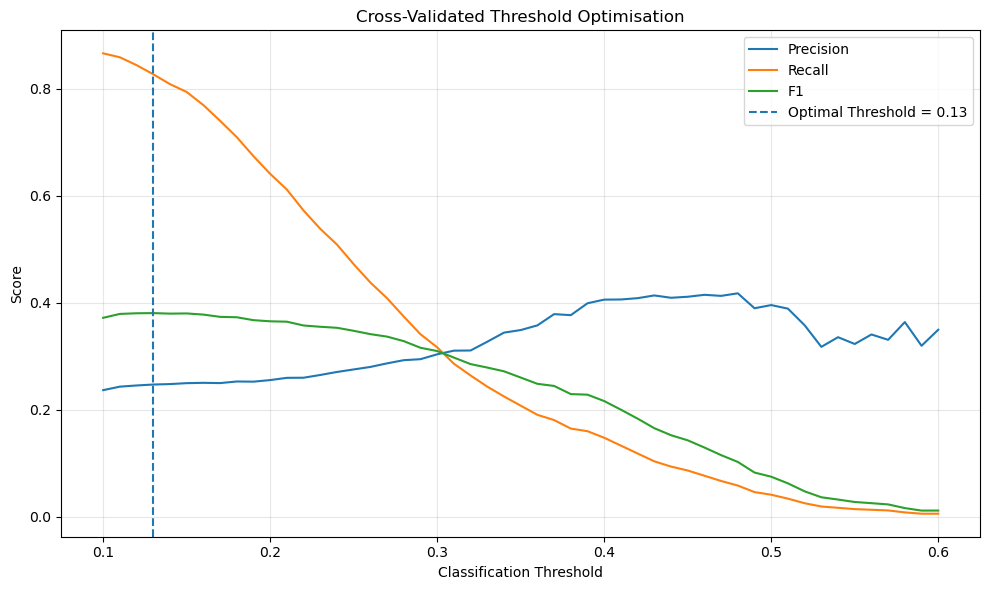

In [23]:
# ============================================================
# THRESHOLD PERFORMANCE PLOT
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    threshold_summary["Threshold"],
    threshold_summary["Precision"],
    label="Precision"
)

plt.plot(
    threshold_summary["Threshold"],
    threshold_summary["Recall"],
    label="Recall"
)

plt.plot(
    threshold_summary["Threshold"],
    threshold_summary["F1"],
    label="F1"
)

plt.axvline(
    optimal_threshold,
    linestyle="--",
    label=(
        f"Optimal Threshold = "
        f"{optimal_threshold:.2f}"
    )
)

plt.xlabel(
    "Classification Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Cross-Validated Threshold Optimisation"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Threshold_Optimisation.png"
    ),
    dpi=300
)

plt.show()

In [24]:
# ============================================================
# FINAL MODEL TRAINING
# ============================================================

print("=" * 70)
print("TRAINING FINAL OPTIMISED MODEL")
print("=" * 70)

best_model.fit(
    X_train,
    y_train
)

print("Final model trained successfully.")

TRAINING FINAL OPTIMISED MODEL
Final model trained successfully.


In [25]:
# ============================================================
# FINAL TEST PREDICTIONS
# ============================================================

test_probabilities = (
    best_model.predict_proba(
        X_test
    )[:, 1]
)


test_predictions_default = (
    test_probabilities >= 0.50
).astype(int)


test_predictions_optimal = (
    test_probabilities >= optimal_threshold
).astype(int)


print("Test predictions generated.")

Test predictions generated.


In [26]:
# ============================================================
# FINAL EVALUATION FUNCTION
# ============================================================

def evaluate_test_predictions(
    y_true,
    predictions,
    probabilities,
    threshold
):

    tn, fp, fn, tp = (
        confusion_matrix(
            y_true,
            predictions
        ).ravel()
    )


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )


    return {

        "Threshold":
            threshold,

        "Accuracy":
            accuracy_score(
                y_true,
                predictions
            ),

        "Precision":
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_true,
                probabilities
            ),

        "Average_Precision":
            average_precision_score(
                y_true,
                probabilities
            ),

        "Balanced_Accuracy":
            balanced_accuracy_score(
                y_true,
                predictions
            ),

        "Specificity":
            specificity,

        "TN":
            tn,

        "FP":
            fp,

        "FN":
            fn,

        "TP":
            tp
    }

In [27]:
# ============================================================
# FINAL TEST SET EVALUATION
# ============================================================

default_results = evaluate_test_predictions(

    y_test,

    test_predictions_default,

    test_probabilities,

    0.50
)


optimal_results = evaluate_test_predictions(

    y_test,

    test_predictions_optimal,

    test_probabilities,

    optimal_threshold
)


final_results = pd.DataFrame(
    [
        default_results,
        optimal_results
    ]
)


print("=" * 70)
print("FINAL TEST SET RESULTS")
print("=" * 70)

display(
    final_results.round(4)
)

FINAL TEST SET RESULTS


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Specificity,TN,FP,FN,TP
0,0.50,0.8965,0.4211,0.0392,0.0717,0.7959,0.3048,0.5165,0.9939,1785,11,196,8
1,0.13,0.7135,0.2427,0.8529,0.3779,0.7959,0.3048,0.7753,0.6977,1253,543,30,174


In [28]:
# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("=" * 70)
print("CLASSIFICATION REPORT — OPTIMISED THRESHOLD")
print("=" * 70)

print(

    classification_report(

        y_test,

        test_predictions_optimal,

        target_names=[
            "Not Churn",
            "Churn"
        ],

        zero_division=0
    )
)

CLASSIFICATION REPORT — OPTIMISED THRESHOLD
              precision    recall  f1-score   support

   Not Churn       0.98      0.70      0.81      1796
       Churn       0.24      0.85      0.38       204

    accuracy                           0.71      2000
   macro avg       0.61      0.78      0.60      2000
weighted avg       0.90      0.71      0.77      2000



Confusion Matrix:
[[1253  543]
 [  30  174]]


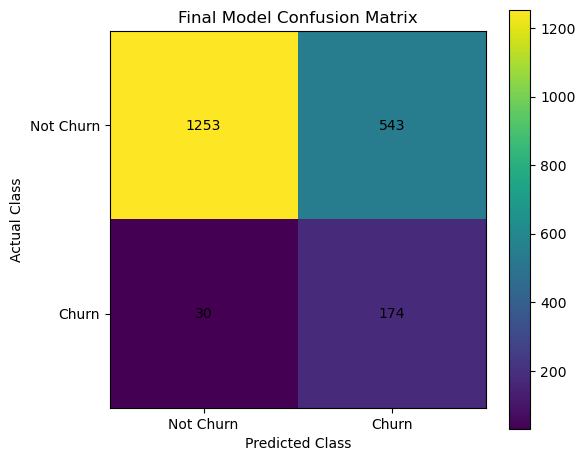

In [29]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(

    y_test,

    test_predictions_optimal
)


print("Confusion Matrix:")
print(cm)


plt.figure(
    figsize=(6, 5)
)

plt.imshow(cm)

plt.title(
    "Final Model Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.xticks(
    [0, 1],
    ["Not Churn", "Churn"]
)

plt.yticks(
    [0, 1],
    ["Not Churn", "Churn"]
)


for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )


plt.colorbar()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "Final_Confusion_Matrix.png"
    ),
    dpi=300
)

plt.show()

In [30]:
# ============================================================
# SAVE FINAL MODEL
# ============================================================

joblib.dump(

    best_model,

    os.path.join(
        OUTPUT_DIR,
        "Best_Optimised_Churn_Model.pkl"
    )
)


print(
    "Final model saved successfully."
)

Final model saved successfully.


In [31]:
# ============================================================
# SAVE OPTIMAL THRESHOLD
# ============================================================

threshold_information = pd.DataFrame({

    "Selected_Model": [
        best_model_name
    ],

    "Optimal_Threshold": [
        optimal_threshold
    ],

    "Threshold_Selection_Metric": [
        "F1"
    ],

    "Cross_Validation": [
        "Stratified 5-Fold"
    ],

    "Random_State": [
        RANDOM_STATE
    ]
})


threshold_information.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Optimal_Threshold.csv"
    ),

    index=False
)


print(
    "Threshold information saved."
)

Threshold information saved.


In [32]:
# ============================================================
# SAVE FINAL RESULTS
# ============================================================

final_results.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Final_Optimised_Model_Test_Results.csv"
    ),

    index=False
)


threshold_summary.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Cross_Validated_Threshold_Results.csv"
    ),

    index=False
)


print(
    "Final evaluation results saved."
)

Final evaluation results saved.


In [33]:
# ============================================================
# SAVE MODEL INFORMATION
# ============================================================

model_information = pd.DataFrame({

    "Item": [

        "Selected Model",

        "Number of Original Features",

        "Training Samples",

        "Test Samples",

        "Cross-Validation",

        "SMOTE",

        "Optimisation Metric",

        "Threshold Metric",

        "Optimal Threshold"
    ],

    "Value": [

        best_model_name,

        X_train.shape[1],

        X_train.shape[0],

        X_test.shape[0],

        "Stratified 5-Fold",

        "Applied inside CV training folds",

        "ROC-AUC",

        "F1",

        optimal_threshold
    ]
})


model_information.to_csv(

    os.path.join(
        OUTPUT_DIR,
        "Model_Optimisation_Information.csv"
    ),

    index=False
)


display(
    model_information
)

,Item,Value
0,Selected Model,XGBoost
1,Number of Original Features,44
2,Training Samples,8000
3,Test Samples,2000
4,Cross-Validation,Stratified 5-Fold
5,SMOTE,Applied inside CV training folds
6,Optimisation Metric,ROC-AUC
7,Threshold Metric,F1
8,Optimal Threshold,0.13


In [34]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("MODEL OPTIMISATION & VALIDATION COMPLETED")
print("=" * 70)

print(
    "\nSelected Model:",
    best_model_name
)

print(
    "Best CV ROC-AUC:",
    round(
        best_search.best_score_,
        4
    )
)

print(
    "Optimal Threshold:",
    round(
        optimal_threshold,
        2
    )
)

print("\nFinal Test Results:")
display(
    final_results.round(4)
)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\n" + "=" * 70)
print("END OF NOTEBOOK 08")
print("=" * 70)


MODEL OPTIMISATION & VALIDATION COMPLETED

Selected Model: XGBoost
Best CV ROC-AUC: 0.8011
Optimal Threshold: 0.13

Final Test Results:


,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision,Balanced_Accuracy,Specificity,TN,FP,FN,TP
0,0.50,0.8965,0.4211,0.0392,0.0717,0.7959,0.3048,0.5165,0.9939,1785,11,196,8
1,0.13,0.7135,0.2427,0.8529,0.3779,0.7959,0.3048,0.7753,0.6977,1253,543,30,174



Output directory:
model_optimisation_results

END OF NOTEBOOK 08
